# Constructing an inference problem

`InferenceProblem` is the common scientific definition consumed by optimizers and, in future, posterior samplers. It combines a declarative model, an observation, and an image grid, then exposes one consistent parameter ordering, prediction, likelihood, prior, and posterior. It does **not** choose how the problem is solved.

This tutorial constructs a problem, inspects its contract, verifies its probability calculation, and passes the same model ingredients to the existing optimizer.

In [1]:
import jax
import matplotlib.pyplot as plt
import numpy as np

from akira import (
    CartesianGrid, CompositeLight, EllipticalPowerLaw, ExternalShear,
    FreeParameter, GaussianPrior, ImagingObservation, InferenceProblem,
    LensModel, LensPlane, ProfileModel, Sersic, UniformPrior, fit_model,
    gaussian_psf, render, simulate_imaging,
)

print(f'JAX version: {jax.__version__}')

JAX version: 0.12.1


## 1. Make a reproducible observation

We first simulate data from ordinary physical profile objects. The observation retains the image, noise map, PSF, mask, and detector pixel scale.

In [2]:
grid = CartesianGrid(shape=(56, 56), pixel_scale=0.05, supersampling=2)
true_lens = LensPlane((
    EllipticalPowerLaw(0.91, slope=2.06, q=0.78, phi=0.25),
    ExternalShear(0.03, phi=0.55),
))
true_source = CompositeLight((
    Sersic(
        intensity=0.12, effective_radius=0.17, sersic_index=1.2,
        centre=(0.06, -0.04), q=0.72, phi=-0.18,
    ),
))
noiseless = render(grid, true_lens, true_source)
observation = simulate_imaging(
    noiseless, gaussian_psf(0.8, size=7), noise_sigma=0.005,
    pixel_scale=grid.pixel_scale, seed=27,
)
print(observation.data.shape, observation.pixel_scale)

(56, 56) 0.05


## 2. Declare fixed and free model values

A `ProfileModel` mirrors a scientific profile. Plain values are fixed. A `FreeParameter` supplies an initial value and normalized prior. Tuple elements may be free independently, as for the two source-centre coordinates below.

The order in which free values are discovered becomes the stable vector order used by every inference method.

In [3]:
model = LensModel(
    lens=(
        ProfileModel(
            EllipticalPowerLaw,
            einstein_radius=FreeParameter(0.86, UniformPrior(0.7, 1.1)),
            slope=FreeParameter(1.95, GaussianPrior(2.0, 0.25)),
            centre=(0.0, 0.0), q=0.78, phi=0.25,
        ),
        ProfileModel(ExternalShear, strength=0.03, phi=0.55),
    ),
    source=(
        ProfileModel(
            Sersic,
            intensity=0.12, effective_radius=0.17, sersic_index=1.2,
            centre=(
                FreeParameter(0.02, UniformPrior(-0.2, 0.2)),
                FreeParameter(0.00, UniformPrior(-0.2, 0.2)),
            ),
            q=0.72, phi=-0.18,
        ),
    ),
)

## 3. Construct and inspect `InferenceProblem`

Construction validates that the observation and grid shapes agree and precomputes the sub-pixel coordinates used by predictions. The public properties below are the contract that optimizers and samplers consume.

In [4]:
problem = InferenceProblem(model, observation, grid)

for name, initial, bounds in zip(
    problem.parameter_names, np.asarray(problem.initial_vector), problem.bounds
):
    print(f'{name:55s} initial={initial: .4f} bounds={bounds}')

lens.0.EllipticalPowerLaw.einstein_radius               initial= 0.8600 bounds=(0.7, 1.1)
lens.0.EllipticalPowerLaw.slope                         initial= 1.9500 bounds=(None, None)
source.0.Sersic.centre.x                                initial= 0.0200 bounds=(-0.2, 0.2)
source.0.Sersic.centre.y                                initial= 0.0000 bounds=(-0.2, 0.2)


## 4. Evaluate one parameter vector

`build_model` creates physical profiles, `predict` renders and PSF-convolves the image, and the three probability methods evaluate the declared statistical model. Because these calculations use JAX, the posterior can be differentiated by gradient-based optimizers and NUTS.

In [5]:
initial = problem.initial_vector
initial_prediction = problem.predict(initial)
log_likelihood = problem.log_likelihood(initial)
log_prior = problem.log_prior(initial)
log_posterior = problem.log_posterior(initial)
gradient = jax.grad(problem.log_posterior)(initial)

print(f'log likelihood: {float(log_likelihood):.3f}')
print(f'log prior:      {float(log_prior):.3f}')
print(f'log posterior:  {float(log_posterior):.3f}')
print('posterior gradient:', np.asarray(gradient))

log likelihood: -282171.888
log prior:      3.196
log posterior:  -282168.692
posterior gradient: [ 4976220.6079934    125534.86100531  2310638.97061527 -4484673.19139897]


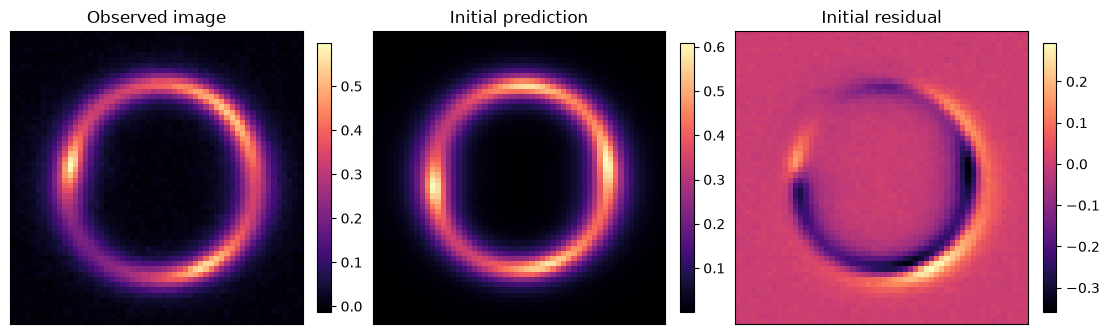

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), constrained_layout=True)
panels = (
    (observation.data, 'Observed image'),
    (initial_prediction, 'Initial prediction'),
    (observation.data - initial_prediction, 'Initial residual'),
)
for axis, (image, title) in zip(axes, panels):
    artist = axis.imshow(np.asarray(image), origin='lower', cmap='magma')
    axis.set_title(title)
    axis.set_xticks([]); axis.set_yticks([])
    fig.colorbar(artist, ax=axis, fraction=0.046)
plt.show()

## 5. Solve the same problem with the current optimizer

The current compatibility API accepts the model, observation, and grid separately, then constructs this same `InferenceProblem` internally. Future samplers will accept the problem directly and evaluate the identical posterior.

In [7]:
result = fit_model(model, observation, grid, mode='map')
print('success:', result.success, '-', result.message)
for name, value in result.parameters.items():
    print(f'{name:55s} {value: .5f}')
print(f'final log posterior: {result.log_posterior:.3f}')

success: True - CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
lens.0.EllipticalPowerLaw.einstein_radius                0.90989
lens.0.EllipticalPowerLaw.slope                          2.05901
source.0.Sersic.centre.x                                 0.06008
source.0.Sersic.centre.y                                -0.04008
final log posterior: 12114.774


## What the problem does—and does not—do

The problem defines the parameter space and probability calculation. It does not optimize, sample, assess convergence, or save results. Those are separate operations. MAP optimization uses `log_posterior` and its gradient; planned NUTS sampling will use the same pair; planned nested sampling will use `log_likelihood` together with `from_unit` to transform unit-cube points through the declared priors.